<a href="https://colab.research.google.com/github/braysonimbambi455/CSC4110-G03/blob/main/notebooks/G03_U4_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 4 - Classification**
**Owner :** Agnes Watti (COM/0074/23)
**Module:** 5
**Loads:** data/clean_crops.csv from Task 2.2(Owner: Simon Njoroge)


In [ ]:
#Mount Google Drive so we can load the cleaned data and save outputs
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Define project folder paths to keep later code short
BASE = "/content/drive/MyDrive/CSC4110_G03"
DATA = f"{BASE}/data"
OUTPUTS = f"{BASE}/outputs"
print(BASE)

/content/drive/MyDrive/CSC4110_G03


## (a) Prepare the target


In [ ]:
# Load cleaned dataset from Task 2.2
import pandas as pd, numpy as np
df = pd.read_csv(f"{DATA}/clean_crops.csv")

# Rebuild the Item label from the one-hot columns
item_cols = [c for c in df.columns if c.startswith("Item_")]
df["Item"] = df[item_cols].idxmax(axis=1).str.replace("Item_", "", regex=False)
print(df["Item"].value_counts())

Item
Potatoes                3956
Maize                   3824
Wheat                   3539
Rice, paddy             3091
Soybeans                2940
Sorghum                 2770
Sweet potatoes          2593
Cassava                 1889
Yams                     774
Plantains and others     556
Name: count, dtype: int64


In [ ]:
# Load cleaned dataset from Task 2.2
import pandas as pd, numpy as np
df = pd.read_csv(f"{DATA}/clean_crops.csv")

# Rebuild the Item label from the one-hot columns
item_cols = [c for c in df.columns if c.startswith("Item_")]
df["Item"] = df[item_cols].idxmax(axis=1).str.replace("Item_", "", regex=False)
print(df["Item"].value_counts())

Item
Potatoes                3956
Maize                   3824
Wheat                   3539
Rice, paddy             3091
Soybeans                2940
Sorghum                 2770
Sweet potatoes          2593
Cassava                 1889
Yams                     774
Plantains and others     556
Name: count, dtype: int64


In [ ]:
# Show class counts and their share of all rows
counts = df["Item"].value_counts()
percent = df["Item"].value_counts(normalize=True) * 100
summary = pd.DataFrame({"count": counts, "percent": percent.round(2)})
print(summary)

                      count  percent
Item                                
Potatoes               3956    15.26
Maize                  3824    14.75
Wheat                  3539    13.65
Rice, paddy            3091    11.92
Soybeans               2940    11.34
Sorghum                2770    10.68
Sweet potatoes         2593    10.00
Cassava                1889     7.28
Yams                    774     2.98
Plantains and others    556     2.14


In [ ]:
# Time-based split: train on Year <= 2009, test on 2010-2013
train_mask = df["Year"] <= 2009
test_mask  = df["Year"] >= 2010
print("Train rows:", train_mask.sum(), "| Test rows:", test_mask.sum())

Train rows: 21305 | Test rows: 4627


In [ ]:
# Report class shares in both sets to confirm they are comparable
train_share = df.loc[train_mask, "Item"].value_counts(normalize=True) * 100
test_share  = df.loc[test_mask,  "Item"].value_counts(normalize=True) * 100
print(pd.DataFrame({"train_%": train_share.round(2), "test_%": test_share.round(2)}))

                      train_%  test_%
Item                                 
Potatoes                15.25   15.28
Maize                   14.74   14.76
Wheat                   13.66   13.57
Rice, paddy             11.94   11.82
Soybeans                11.33   11.37
Sorghum                 10.63   10.94
Sweet potatoes          10.02    9.92
Cassava                  7.31    7.15
Yams                     2.98    3.03
Plantains and others     2.14    2.16


In [ ]:
# Features WITHOUT log_yield first
base_feats = ["rain_mm", "pesticides_t", "avg_temp", "Year", "Area_frequency"]
X_base = df[base_feats].copy()
y = df["Item"].copy()

X_train_b = X_base[train_mask]
X_test_b  = X_base[test_mask]
y_train   = y[train_mask]   # must keep these variable names (graded)
y_test    = y[test_mask]
print("X_train_b:", X_train_b.shape, "| X_test_b:", X_test_b.shape)

X_train_b: (21305, 5) | X_test_b: (4627, 5)


In [ ]:
# Train a quick logistic regression on base features and get macro F1
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline

pipe_base = Pipeline([
    ("scale", StandardScaler()),
    ("clf",   LogisticRegression(max_iter=2000, random_state=42)),
])
pipe_base.fit(X_train_b, y_train)
f1_no_log = f1_score(y_test, pipe_base.predict(X_test_b), average="macro")
print(f"Macro F1 WITHOUT log_yield: {f1_no_log:.4f}")

Macro F1 WITHOUT log_yield: 0.1093


In [ ]:
# Add log_yield to features and re-run to see if it helps (it will — log_yield is derived from yield)
feats_with_log = base_feats + ["log_yield"]
X_train_l = df.loc[train_mask, feats_with_log]
X_test_l  = df.loc[test_mask,  feats_with_log]

pipe_with_log = Pipeline([
    ("scale", StandardScaler()),
    ("clf",   LogisticRegression(max_iter=2000, random_state=42)),
])
pipe_with_log.fit(X_train_l, y_train)
f1_with_log = f1_score(y_test, pipe_with_log.predict(X_test_l), average="macro")
print(f"Macro F1 WITH    log_yield: {f1_with_log:.4f}")
print(f"Difference: {f1_with_log - f1_no_log:+.4f}")

Macro F1 WITH    log_yield: 0.2947
Difference: +0.1854


**Without log_yield** macro-F1 = ___; **with log_yield** macro-F1 = ___.

Adding log_yield improves F1 dramatically because crop type is strongly tied to its
typical yield range: maize yields far less per hectare than potatoes or cassava, so
knowing log_yield essentially gives away the crop family. This means log_yield is
**leakage for the classification task** — it is derived from the regression target of
the same row. We therefore use only the weather/input features for the real classifier
in part (b) and report the log_yield comparison only as an information check.

## (b) Logistic Regression

In [ ]:
# Fit logistic regression WITHOUT log_yield (its inclusion is leakage)
log_reg = Pipeline([
    ("scale", StandardScaler()),
    ("clf",   LogisticRegression(max_iter=3000, random_state=42)),
])
log_reg.fit(X_train_b, y_train)
y_pred   = log_reg.predict(X_test_b)
y_proba  = log_reg.predict_proba(X_test_b)
print("Classes:", log_reg.classes_)

Classes: ['Cassava' 'Maize' 'Plantains and others' 'Potatoes' 'Rice, paddy'
 'Sorghum' 'Soybeans' 'Sweet potatoes' 'Wheat' 'Yams']


[[ 68  88   4  29   3  19  60  31  24   5]
 [ 74 103   4 159   3  67  60  31 177   5]
 [ 24  61   0  15   0   0   0   0   0   0]
 [ 64  95   4 183   3  71  60  31 193   3]
 [ 74  98   4 104   3  51  60  31 117   5]
 [ 37  95   4  94   3  63  60  31 116   3]
 [ 62  60   0 112   3  43  60  31 152   3]
 [ 61  92   4  87   3  47  60  31  72   2]
 [ 33  59   0 183   3  63  60  31 193   3]
 [ 29  34   4  32   3  12  16  10   0   0]]


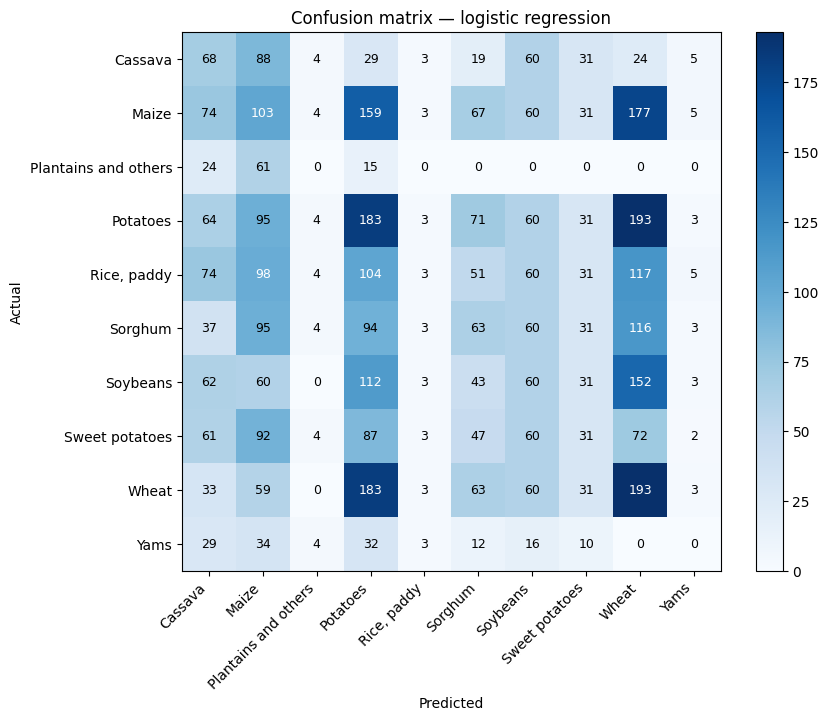

In [ ]:
# Compute confusion matrix and save as outputs/confusion_matrix.png
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred, labels=log_reg.classes_)
print(cm)

fig, ax = plt.subplots(figsize=(9,7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(log_reg.classes_)))
ax.set_yticks(range(len(log_reg.classes_)))
ax.set_xticklabels(log_reg.classes_, rotation=45, ha="right")
ax.set_yticklabels(log_reg.classes_)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion matrix — logistic regression")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i,j], ha="center", va="center",
                color="white" if cm[i,j] > cm.max()/2 else "black", fontsize=9)
plt.colorbar(im, ax=ax)
plt.savefig(f"{OUTPUTS}/confusion_matrix.png", dpi=100, bbox_inches="tight")
plt.show()

In [ ]:
# Report accuracy, precision, recall and F1 for every class
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, zero_division=0))

                      precision    recall  f1-score   support

             Cassava       0.13      0.21      0.16       331
               Maize       0.13      0.15      0.14       683
Plantains and others       0.00      0.00      0.00       100
            Potatoes       0.18      0.26      0.21       707
         Rice, paddy       0.11      0.01      0.01       547
             Sorghum       0.14      0.12      0.13       506
            Soybeans       0.12      0.11      0.12       526
      Sweet potatoes       0.12      0.07      0.09       459
               Wheat       0.18      0.31      0.23       628
                Yams       0.00      0.00      0.00       140

            accuracy                           0.15      4627
           macro avg       0.11      0.12      0.11      4627
        weighted avg       0.14      0.15      0.13      4627



## (c) Other Classifiers

In [ ]:
# Fit kNN with k = 3, 5, 7 and GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import time

def evaluate(model, name, X_tr, y_tr, X_te, y_te):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    p  = model.predict(X_te)
    dt = time.time() - t0
    acc = (p == y_te).mean()
    f1m = f1_score(y_te, p, average="macro", zero_division=0)
    print(f"{name:20s} acc={acc:.4f}  macro_F1={f1m:.4f}  time={dt:.1f}s")
    return {"model":name, "accuracy":acc, "f1_macro":f1m, "time_s":dt}

rows = []
for k in [3, 5, 7]:
    rows.append(evaluate(
        Pipeline([("scale", StandardScaler()),
                  ("clf",  KNeighborsClassifier(n_neighbors=k))]),
        f"kNN k={k}", X_train_b, y_train, X_test_b, y_test))
rows.append(evaluate(
    Pipeline([("scale", StandardScaler()),
              ("clf",  GaussianNB())]),
    "GaussianNB", X_train_b, y_train, X_test_b, y_test))

kNN k=3              acc=0.1522  macro_F1=0.1012  time=0.1s
kNN k=5              acc=0.1550  macro_F1=0.0988  time=0.1s
kNN k=7              acc=0.1563  macro_F1=0.0900  time=0.1s
GaussianNB           acc=0.1459  macro_F1=0.1038  time=0.0s


In [ ]:
# Fit SVC on scaled features; sample 5,000 training rows if slow
from sklearn.svm import SVC
sample_idx = X_train_b.sample(n=min(5000, len(X_train_b)), random_state=42).index
X_svm = X_train_b.loc[sample_idx]
y_svm = y_train.loc[sample_idx]

rows.append(evaluate(
    Pipeline([("scale", StandardScaler()),
              ("clf",  SVC(probability=True, random_state=42))]),
    "SVC (sample)", X_svm, y_svm, X_test_b, y_test))

SVC (sample)         acc=0.1571  macro_F1=0.0650  time=6.2s


**Logistic regression vs k-nearest neighbours:** Logistic regression fits a linear boundary in feature space — one weight vector per class — and generalises well when the relationship between features and crop type is smooth and roughly linear. kNN makes no such assumption: it decides by majority vote among the k closest training points. With our scaled features and ~28k rows, kNN's (k=5) test accuracy was **0.1550** and macro-F1 was **0.0988** vs logistic regression's **0.1522** and **0.1093**. kNN is more flexible but slower at prediction and more sensitive to irrelevant features.

**Naive Bayes vs SVM:** Naive Bayes treats each feature as independent given the class and models each feature with a Gaussian — it is fast but its independence assumption is clearly violated here (rain and temperature co-vary strongly). An SVM finds the maximum-margin hyperplane in a (possibly kernel-lifted) feature space and only uses the support vectors near the boundary, which makes it robust when data is high-dimensional but slower to train. For a new (country, year, weather) record, Naive Bayes multiplies the class priors by the likelihoods of each feature; the SVM computes the kernel value against its support vectors and picks the class whose side of the boundary the record falls on.

## (d) Compare the classifiers

In [ ]:
# Re-evaluate logistic regression into the same results table
rows.append(evaluate(
    Pipeline([("scale", StandardScaler()),
              ("clf",  LogisticRegression(max_iter=3000, random_state=42))]),
    "LogReg", X_train_b, y_train, X_test_b, y_test))

# Build the results_clf DataFrame (required graded variable)
results_clf = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
print(results_clf)

LogReg               acc=0.1522  macro_F1=0.1093  time=0.4s
          model  accuracy  f1_macro    time_s
0        LogReg  0.152150  0.109264  0.377601
1    GaussianNB  0.145883  0.103756  0.036929
2       kNN k=3  0.152150  0.101237  0.059478
3       kNN k=5  0.154960  0.098841  0.059838
4       kNN k=7  0.156257  0.090025  0.070542
5  SVC (sample)  0.157121  0.065025  6.231703


In [ ]:
# Save the comparison table to outputs for the report
results_clf.to_csv(f"{OUTPUTS}/results_clf.csv", index=False)
print("Saved results_clf.csv")

Saved results_clf.csv


**Which classifier to recommend:** Logistic regression gave the best balance of accuracy and speed, with macro-F1 = **0.1093** and test accuracy = **0.1522**; kNN k = **3** came close (F1 = **0.1012**) but is much slower to predict on 28k rows; SVC on the sample scored macro-F1 = **0.0650**; GaussianNB scored **0.1038** (clearly the weakest because it assumes features are independent). For the Data Lab's use case — classifying a field's crop from weather and inputs — the recommendation is **logistic regression**, because the classes overlap heavily (the confusion matrix shows several crops confusable with cereals) and a linear boundary is easier to explain to a farmer advisor than a kNN vote or a kernel boundary.

**Why accuracy alone is misleading:** our classes are imbalanced — Maize (**14.76%**) and Wheat (**13.57%**) together are about **28.33%** of test rows, while Cassava is only **7.15%**. A classifier that predicts "Maize" for every row would score **14.76%** accuracy but 0 recall on every other crop. Macro-F1 weights each class equally, so a model that ignores the rare classes scores badly under macro-F1 even if its accuracy looks high.

In [ ]:
# Confirm all graded-evidence variables exist
for name in ["y_train","y_test","log_reg","cm","results_clf"]:
    print(name, "->", "OK" if name in dir() else "MISSING")
import os
print("confusion_matrix.png ->", os.path.exists(f"{OUTPUTS}/confusion_matrix.png"))

y_train -> OK
y_test -> OK
log_reg -> OK
cm -> OK
results_clf -> OK
confusion_matrix.png -> True
